
# R3 — Comparison with Alternative Explainability Methods

This notebook evaluates the existing CLARITY-PD models on the fixed held-out test set using:

1. **SHAP** — the existing feature-attribution implementation.
2. **LIME** — model-agnostic local feature attribution.
3. **Integrated Gradients (IG)** — gradient-based attribution for the differentiable NN expert.
4. **Counterfactual explanations** — constrained perturbations on the complete adaptive prediction pipeline.

### Methodological boundary

SHAP, LIME, and Integrated Gradients are compared at the **feature-attribution level on the same 18-input neural-network expert**. This is the cleanest apples-to-apples comparison because Integrated Gradients requires a differentiable model and the Random Forest branch is not differentiable.

Counterfactuals operate on the **complete adaptive CLARITY-PD pipeline** (RF + NN + adaptive gate), because they answer a different question: what plausible input changes would move the final severity prediction toward a specified target?

The predictive models are **not retrained**. The existing fixed train/validation/test split and exported artifacts are reused.


In [1]:

import os
import json
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import joblib

import torch
import torch.nn as nn

import shap
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)


Using device: cuda


In [2]:

# Fixed exported data
ROOT = Path("..")
DATA_DIR = ROOT / "data" / "processed"
MODEL_DIR = ROOT / "models"

X_scaler = joblib.load(DATA_DIR / "X_scaler.pkl")
y_scaler = joblib.load(DATA_DIR / "y_scaler.pkl")

X_train = np.load(DATA_DIR / "X_train.npy")
X_val = np.load(DATA_DIR / "X_val.npy")
X_test = np.load(DATA_DIR / "X_test.npy")

y_train = np.load(DATA_DIR / "y_train.npy")
y_val = np.load(DATA_DIR / "y_val.npy")
y_test = np.load(DATA_DIR / "y_test.npy")

with open(DATA_DIR / "feature_names.json", "r") as f:
    feature_names = list(json.load(f))

print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)
print("Features:", len(feature_names))


X_train: (3760, 18)
X_val  : (940, 18)
X_test : (1175, 18)
Features: 18


In [3]:

# Exact architectures from the existing training/gating notebooks
with open(MODEL_DIR / "best_nn_params.json", "r") as f:
    nn_params = json.load(f)

class FinalParkinsonNN(nn.Module):
    def __init__(self, params, input_dim=18):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, params["units_l1"]), nn.ReLU(),
            nn.Linear(params["units_l1"], params["units_l2"]), nn.ReLU(),
            nn.Dropout(params["dropout"]),
            nn.Linear(params["units_l2"], params["units_l3"]), nn.ReLU(),
            nn.Linear(params["units_l3"], params["units_l4"]), nn.ReLU(),
            nn.Linear(params["units_l4"], 2)
        )

    def forward(self, x):
        return self.net(x)

class AdaptiveGate(nn.Module):
    def __init__(self, input_dim, hidden_dim, dropout_rate, temperature):
        super().__init__()
        self.temperature = temperature
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(hidden_dim, 2)
        )

    def forward(self, x):
        logits = self.net(x)
        return torch.softmax(logits / self.temperature, dim=1)

nn_model = FinalParkinsonNN(nn_params).to(DEVICE)
nn_model.load_state_dict(torch.load(
    MODEL_DIR / "best_nn_model.pt", map_location=DEVICE
))
nn_model.eval()

rf_expert = joblib.load(MODEL_DIR / "rf_expert.pkl")

with open(MODEL_DIR / "best_motor_gate_params.json", "r") as f:
    motor_params = json.load(f)
with open(MODEL_DIR / "best_total_gate_params.json", "r") as f:
    total_params = json.load(f)

motor_gate = AdaptiveGate(
    input_dim=22,
    hidden_dim=motor_params["hidden_dim"],
    dropout_rate=motor_params["dropout_rate"],
    temperature=motor_params["temperature"],
).to(DEVICE)

total_gate = AdaptiveGate(
    input_dim=22,
    hidden_dim=total_params["hidden_dim"],
    dropout_rate=total_params["dropout_rate"],
    temperature=total_params["temperature"],
).to(DEVICE)

motor_gate.load_state_dict(torch.load(
    MODEL_DIR / "motor_gate.pt", map_location=DEVICE
))
total_gate.load_state_dict(torch.load(
    MODEL_DIR / "total_gate.pt", map_location=DEVICE
))

motor_gate.eval()
total_gate.eval()

print("All four trained components loaded.")


All four trained components loaded.


In [4]:

# Exact adaptive prediction pipeline
@torch.no_grad()
def nn_predict_scaled(X):
    X_t = torch.tensor(np.asarray(X), dtype=torch.float32, device=DEVICE)
    return nn_model(X_t).cpu().numpy()

def rf_predict_scaled(X):
    return np.asarray(rf_expert.predict(np.asarray(X)))

@torch.no_grad()
def gate_weights(X):
    X = np.asarray(X)
    rf_p = rf_predict_scaled(X)
    nn_p = nn_predict_scaled(X)
    gate_input = np.concatenate([X, rf_p, nn_p], axis=1)
    gate_t = torch.tensor(gate_input, dtype=torch.float32, device=DEVICE)
    mw = motor_gate(gate_t).cpu().numpy()
    tw = total_gate(gate_t).cpu().numpy()
    return rf_p, nn_p, mw, tw

def adaptive_predict_scaled(X):
    rf_p, nn_p, mw, tw = gate_weights(X)
    motor = mw[:, 0] * rf_p[:, 0] + mw[:, 1] * nn_p[:, 0]
    total = tw[:, 0] * rf_p[:, 1] + tw[:, 1] * nn_p[:, 1]
    return np.column_stack([motor, total])

def adaptive_predict_raw(X_raw):
    X_scaled = X_scaler.transform(np.asarray(X_raw))
    return y_scaler.inverse_transform(adaptive_predict_scaled(X_scaled))

nn_test_preds_scaled = nn_predict_scaled(X_test)
rf_test_preds_scaled = rf_predict_scaled(X_test)
adaptive_test_preds_scaled = adaptive_predict_scaled(X_test)
adaptive_test_preds_raw = y_scaler.inverse_transform(adaptive_test_preds_scaled)

_, _, motor_weights, total_weights = gate_weights(X_test)

print("Adaptive prediction matrix:", adaptive_test_preds_raw.shape)


Adaptive prediction matrix: (1175, 2)


In [5]:

# Representative 20-sample held-out test subset
routing_df = pd.DataFrame({
    "test_index": np.arange(len(X_test)),
    "motor_rf": motor_weights[:, 0],
    "motor_nn": motor_weights[:, 1],
    "total_rf": total_weights[:, 0],
    "total_nn": total_weights[:, 1],
    "motor_pred": adaptive_test_preds_raw[:, 0],
    "total_pred": adaptive_test_preds_raw[:, 1],
})

routing_df["severity"] = pd.qcut(
    routing_df["motor_pred"], q=3,
    labels=["low", "medium", "high"],
    duplicates="drop"
)

routing_df["routing_pattern"] = np.where(
    routing_df["motor_rf"] >= 0.80,
    "RF-dominant",
    np.where(routing_df["motor_nn"] >= 0.40, "NN-contributing", "mixed")
)

rng = np.random.default_rng(SEED)
selected = []

for severity in ["low", "medium", "high"]:
    for pattern in ["RF-dominant", "NN-contributing", "mixed"]:
        pool = routing_df[
            (routing_df["severity"].astype(str) == severity) &
            (routing_df["routing_pattern"] == pattern)
        ]["test_index"].to_numpy()
        if len(pool):
            selected.extend(
                rng.choice(pool, size=min(2, len(pool)), replace=False).tolist()
            )

selected = list(dict.fromkeys(selected))
remaining = [i for i in range(len(X_test)) if i not in selected]

if len(selected) < 20:
    selected.extend(
        rng.choice(
            remaining,
            size=min(20 - len(selected), len(remaining)),
            replace=False
        ).tolist()
    )

selected = sorted(selected[:20])
sample_df = routing_df[routing_df["test_index"].isin(selected)].copy()

print("Selected test indices:", selected)
display(sample_df)


Selected test indices: [63, 105, 163, 248, 473, 481, 483, 487, 552, 612, 641, 733, 832, 844, 869, 870, 896, 934, 968, 991]


,test_index,motor_rf,motor_nn,total_rf,total_nn,motor_pred,total_pred,severity,routing_pattern
63,63,0.902828,0.097172,0.903015,0.096985,13.332903,19.373448,low,RF-dominant
105,105,0.754644,0.245356,0.895026,0.104974,13.536540,19.603452,low,mixed
163,163,0.841822,0.158178,0.639707,0.360293,24.483108,32.002695,medium,RF-dominant
248,248,0.587003,0.412997,0.545113,0.454887,25.707718,31.279224,high,NN-contributing
473,473,0.502744,0.497256,0.580087,0.419912,16.480798,25.850974,low,NN-contributing
481,481,0.519536,0.480464,0.566550,0.433450,11.227735,16.673348,low,NN-contributing
483,483,0.594099,0.405901,0.543292,0.456708,29.623481,40.069132,high,NN-contributing
487,487,0.941684,0.058316,0.891326,0.108674,28.427426,37.314184,high,RF-dominant
552,552,0.724549,0.275452,0.790677,0.209323,17.499379,25.700330,medium,mixed
612,612,0.994561,0.005439,0.983289,0.016710,21.150540,28.697674,medium,RF-dominant


In [6]:

# LIME
try:
    from lime.lime_tabular import LimeTabularExplainer
except ImportError as e:
    raise ImportError("Install LIME with: pip install lime") from e

lime_explainer = LimeTabularExplainer(
    training_data=X_train,
    feature_names=feature_names,
    mode="regression",
    discretize_continuous=False,
    random_state=SEED,
)

def make_lime_prediction_fn(output_idx):
    def predict_fn(X):
        return nn_predict_scaled(np.asarray(X))[:, output_idx]
    return predict_fn


In [7]:
# ============================================================
# Integrated Gradients — faster version
# ============================================================

try:
    from captum.attr import IntegratedGradients
except ImportError as e:
    raise ImportError("Install Captum with: pip install captum") from e


class SingleOutputNN(nn.Module):
    def __init__(self, base_model, output_idx):
        super().__init__()
        self.base_model = base_model
        self.output_idx = output_idx

    def forward(self, x):
        return self.base_model(x)[:, self.output_idx]


ig_models = {
    0: SingleOutputNN(nn_model, 0).to(DEVICE),
    1: SingleOutputNN(nn_model, 1).to(DEVICE),
}

ig_baseline = torch.tensor(
    X_train.mean(axis=0, keepdims=True),
    dtype=torch.float32,
    device=DEVICE
)


def integrated_gradients_attribution(x_row, output_idx):
    ig = IntegratedGradients(ig_models[output_idx])

    x = torch.tensor(
        np.asarray(x_row, dtype=np.float32).reshape(1, -1),
        device=DEVICE
    )

    attr = ig.attribute(
        x,
        baselines=ig_baseline,
        n_steps=50,
        internal_batch_size=1,
    )

    return attr.detach().cpu().numpy()[0]

In [8]:

# SHAP — same NN expert used by the existing explainability notebook
shap_background = torch.tensor(
    X_train[:min(100, len(X_train))],
    dtype=torch.float32,
    device=DEVICE
)

shap_explainer = shap.GradientExplainer(nn_model, shap_background)

def shap_nn_attribution(x_row):
    x = torch.tensor(
        np.asarray(x_row, dtype=np.float32).reshape(1, -1),
        device=DEVICE
    )

    values = shap_explainer.shap_values(x)

    if isinstance(values, list):
        return {
            0: np.asarray(values[0])[0],
            1: np.asarray(values[1])[0],
        }

    arr = np.asarray(values)

    if arr.ndim == 3 and arr.shape[-1] == 2:
        return {
            0: arr[0, :, 0],
            1: arr[0, :, 1],
        }

    if arr.ndim == 3 and arr.shape[1] == 2:
        return {
            0: arr[0, 0, :],
            1: arr[0, 1, :],
        }

    raise ValueError(f"Unexpected SHAP shape: {arr.shape}")


In [9]:

# Attribution comparison helpers
TOP_K = 5

def top_k_indices(values, k=TOP_K):
    return np.argsort(np.abs(np.asarray(values)))[::-1][:k]

def top_k_names(values, k=TOP_K):
    return [feature_names[i] for i in top_k_indices(values, k)]

def overlap_at_k(a, b, k=TOP_K):
    return len(
        set(top_k_indices(a, k)) & set(top_k_indices(b, k))
    ) / float(k)

def rank_vector(values):
    order = np.argsort(np.abs(values))[::-1]
    ranks = np.empty(len(values), dtype=float)
    ranks[order] = np.arange(1, len(values) + 1)
    return ranks

def rank_corr(a, b):
    return float(spearmanr(rank_vector(a), rank_vector(b)).statistic)


In [10]:
# ============================================================
# Fast batched counterfactual search
# ============================================================

IMMUTABLE_FEATURES = {"age", "sex"}

PERTURBABLE = [
    i for i, name in enumerate(feature_names)
    if name not in IMMUTABLE_FEATURES
]

# Keep counterfactuals inside the training-data support.
feature_low = np.percentile(X_train, 1, axis=0)
feature_high = np.percentile(X_train, 99, axis=0)

y_train_raw = y_scaler.inverse_transform(y_train)
target_std_raw = y_train_raw.std(axis=0)


def adaptive_target_prediction(X, target_idx):
    """
    Batched final CLARITY-PD prediction in raw UPDRS units.
    """
    X = np.asarray(X)

    pred_scaled = adaptive_predict_scaled(X)
    pred_raw = y_scaler.inverse_transform(pred_scaled)

    return pred_raw[:, target_idx]


def fast_counterfactual_search(
    x0_scaled,
    target_idx,
    direction,
    step_sizes=(0.10, 0.20, 0.40),
    max_steps=4,
):
    """
    Greedy coordinate-search counterfactual.

    At each iteration:
      1. Generate all one-feature candidate perturbations.
      2. Evaluate candidates in ONE batched CLARITY-PD call.
      3. Choose the candidate closest to the desired target with
         minimum perturbation magnitude as the tie-breaker.

    direction:
        -1 -> seek lower predicted severity
        +1 -> seek higher predicted severity
    """

    x0 = np.asarray(x0_scaled, dtype=float).copy()
    current = x0.copy()

    original_prediction = float(
        adaptive_target_prediction(
            current.reshape(1, -1),
            target_idx
        )[0]
    )

    target_shift = 0.10 * target_std_raw[target_idx]
    desired_prediction = (
        original_prediction +
        direction * target_shift
    )

    def reached(pred):
        if direction < 0:
            return pred <= desired_prediction
        return pred >= desired_prediction

    for iteration in range(max_steps):

        current_prediction = float(
            adaptive_target_prediction(
                current.reshape(1, -1),
                target_idx
            )[0]
        )

        if reached(current_prediction):
            break

        candidates = []
        metadata = []

        # Generate one-feature candidates.
        for feature_idx in PERTURBABLE:
            for step in step_sizes:
                for sign in (-1.0, 1.0):

                    candidate = current.copy()

                    candidate[feature_idx] += sign * step

                    candidate[feature_idx] = np.clip(
                        candidate[feature_idx],
                        feature_low[feature_idx],
                        feature_high[feature_idx],
                    )

                    # Ignore candidates that actually made no change.
                    if np.isclose(
                        candidate[feature_idx],
                        current[feature_idx]
                    ):
                        continue

                    candidates.append(candidate)
                    metadata.append(
                        (feature_idx, candidate[feature_idx] - current[feature_idx])
                    )

        if not candidates:
            break

        candidates = np.asarray(candidates)

        # ----------------------------------------------------
        # IMPORTANT: evaluate every candidate in one batch
        # ----------------------------------------------------
        predictions = adaptive_target_prediction(
            candidates,
            target_idx
        )

        # Score candidates.
        scores = []

        for pred, (feature_idx, delta) in zip(
            predictions,
            metadata
        ):

            pred = float(pred)

            if direction < 0:
                gap = max(
                    0.0,
                    pred - desired_prediction
                )
            else:
                gap = max(
                    0.0,
                    desired_prediction - pred
                )

            # Primary objective = reach the desired prediction.
            # Secondary objective = small standardized change.
            l1_distance = float(
                np.sum(np.abs(candidates[
                    len(scores)
                ] - x0))
            )

            reached_flag = reached(pred)

            score = (
                0 if reached_flag else 1,
                gap,
                l1_distance,
            )

            scores.append(score)

        best_idx = min(
            range(len(scores)),
            key=lambda i: scores[i]
        )

        current = candidates[best_idx]

    # Final evaluation.
    final_prediction = float(
        adaptive_target_prediction(
            current.reshape(1, -1),
            target_idx
        )[0]
    )

    changed_mask = ~np.isclose(
        current,
        x0,
        atol=1e-10
    )

    return {
        "success": bool(reached(final_prediction)),
        "x_cf": current,
        "original_prediction": original_prediction,
        "desired_prediction": desired_prediction,
        "counterfactual_prediction": final_prediction,
        "prediction_change": (
            final_prediction - original_prediction
        ),
        "changed_features": int(changed_mask.sum()),
        "l1_distance": float(
            np.sum(np.abs(current - x0))
        ),
    }


def changed_feature_details(x0, xcf):
    rows = []

    for i, name in enumerate(feature_names):
        if not np.isclose(x0[i], xcf[i]):
            rows.append({
                "feature": name,
                "delta_standardized": xcf[i] - x0[i],
                "original_standardized": x0[i],
                "counterfactual_standardized": xcf[i],
            })

    return pd.DataFrame(rows)

In [11]:
# ============================================================
# Run SHAP, LIME, IG and counterfactuals — optimized version
# ============================================================

attribution_rows = []
counterfactual_rows = []

for sample_num, sample_idx in enumerate(selected, start=1):

    print(
        f"Processing sample {sample_num}/{len(selected)} "
        f"(test index {sample_idx})..."
    )

    x = X_test[sample_idx].copy()

    # SHAP once per patient.
    shap_map = shap_nn_attribution(x)

    for target_idx, target_name in [
        (0, "Motor-UPDRS"),
        (1, "Total-UPDRS")
    ]:

        # ----------------------------------------------------
        # LIME
        # ----------------------------------------------------
        lime_exp = lime_explainer.explain_instance(
            x,
            make_lime_prediction_fn(target_idx),
            num_features=len(feature_names),
            num_samples=500,
        )

        lime_dict = dict(lime_exp.as_list())

        lime_attr = np.array(
            [
                lime_dict.get(name, 0.0)
                for name in feature_names
            ],
            dtype=float
        )

        # ----------------------------------------------------
        # Integrated Gradients
        # ----------------------------------------------------
        ig_attr = integrated_gradients_attribution(
            x,
            target_idx
        )

        # ----------------------------------------------------
        # SHAP
        # ----------------------------------------------------
        shap_attr = shap_map[target_idx]

        # ----------------------------------------------------
        # Attribution comparison
        # ----------------------------------------------------
        row = {
            "test_index": sample_idx,
            "target": target_name,

            "actual":
                y_test[sample_idx, target_idx],

            "adaptive_prediction":
                adaptive_test_preds_raw[
                    sample_idx,
                    target_idx
                ],

            "motor_rf_weight":
                motor_weights[sample_idx, 0],

            "motor_nn_weight":
                motor_weights[sample_idx, 1],

            "total_rf_weight":
                total_weights[sample_idx, 0],

            "total_nn_weight":
                total_weights[sample_idx, 1],

            "SHAP_top5":
                "; ".join(top_k_names(shap_attr)),

            "LIME_top5":
                "; ".join(top_k_names(lime_attr)),

            "IG_top5":
                "; ".join(top_k_names(ig_attr)),

            "SHAP_LIME_Overlap5":
                overlap_at_k(
                    shap_attr,
                    lime_attr
                ),

            "SHAP_IG_Overlap5":
                overlap_at_k(
                    shap_attr,
                    ig_attr
                ),

            "LIME_IG_Overlap5":
                overlap_at_k(
                    lime_attr,
                    ig_attr
                ),

            "SHAP_LIME_Spearman":
                rank_corr(
                    shap_attr,
                    lime_attr
                ),

            "SHAP_IG_Spearman":
                rank_corr(
                    shap_attr,
                    ig_attr
                ),

            "LIME_IG_Spearman":
                rank_corr(
                    lime_attr,
                    ig_attr
                ),
        }

        # Store complete attribution vectors.
        for i, fname in enumerate(feature_names):
            row[f"SHAP::{fname}"] = shap_attr[i]
            row[f"LIME::{fname}"] = lime_attr[i]
            row[f"IG::{fname}"] = ig_attr[i]

        attribution_rows.append(row)

        # ----------------------------------------------------
        # Counterfactuals
        # ----------------------------------------------------
        for direction, direction_name in [
            (-1, "lower"),
            (1, "higher")
        ]:

            cf = fast_counterfactual_search(
                x,
                target_idx=target_idx,
                direction=direction,
            )

            changed = changed_feature_details(
                x,
                cf["x_cf"]
            )

            counterfactual_rows.append({
                "test_index": sample_idx,
                "target": target_name,
                "direction": direction_name,

                "success":
                    cf["success"],

                "original_prediction":
                    cf["original_prediction"],

                "desired_prediction":
                    cf["desired_prediction"],

                "counterfactual_prediction":
                    cf["counterfactual_prediction"],

                "prediction_change":
                    cf["prediction_change"],

                "changed_features":
                    cf["changed_features"],

                "l1_distance":
                    cf["l1_distance"],

                "changed_feature_names":
                    "; ".join(
                        changed["feature"].tolist()
                    )
                    if len(changed)
                    else "",
            })

# ------------------------------------------------------------
# Final dataframes
# ------------------------------------------------------------

results_df = pd.DataFrame(attribution_rows)
counterfactual_df = pd.DataFrame(counterfactual_rows)

print()
print("==============================================")
print("R3 XAI comparison complete")
print("==============================================")
print("Attribution rows:", len(results_df))
print("Counterfactual rows:", len(counterfactual_df))

Processing sample 1/20 (test index 63)...
Processing sample 2/20 (test index 105)...
Processing sample 3/20 (test index 163)...
Processing sample 4/20 (test index 248)...
Processing sample 5/20 (test index 473)...
Processing sample 6/20 (test index 481)...
Processing sample 7/20 (test index 483)...
Processing sample 8/20 (test index 487)...
Processing sample 9/20 (test index 552)...
Processing sample 10/20 (test index 612)...
Processing sample 11/20 (test index 641)...
Processing sample 12/20 (test index 733)...
Processing sample 13/20 (test index 832)...
Processing sample 14/20 (test index 844)...
Processing sample 15/20 (test index 869)...
Processing sample 16/20 (test index 870)...
Processing sample 17/20 (test index 896)...
Processing sample 18/20 (test index 934)...
Processing sample 19/20 (test index 968)...
Processing sample 20/20 (test index 991)...

R3 XAI comparison complete
Attribution rows: 40
Counterfactual rows: 80


In [12]:

# Aggregate feature-attribution comparison
summary_metrics = (
    results_df.groupby("target")[
        [
            "SHAP_LIME_Overlap5",
            "SHAP_IG_Overlap5",
            "LIME_IG_Overlap5",
            "SHAP_LIME_Spearman",
            "SHAP_IG_Spearman",
            "LIME_IG_Spearman",
        ]
    ]
    .mean()
    .reset_index()
)

display(summary_metrics)

# Counterfactual summary
cf_summary = (
    counterfactual_df
    .groupby(["target", "direction"])
    .agg(
        success_rate=("success", "mean"),
        mean_changed_features=("changed_features", "mean"),
        median_changed_features=("changed_features", "median"),
        mean_l1_distance=("l1_distance", "mean"),
        mean_prediction_change=("prediction_change", "mean"),
    )
    .reset_index()
)

display(cf_summary)


,target,SHAP_LIME_Overlap5,SHAP_IG_Overlap5,LIME_IG_Overlap5,SHAP_LIME_Spearman,SHAP_IG_Spearman,LIME_IG_Spearman
0,Motor-UPDRS,0.44,0.73,0.47,0.202064,0.579670,0.175335
1,Total-UPDRS,0.53,0.63,0.48,0.364190,0.473684,0.289061


,target,direction,success_rate,mean_changed_features,median_changed_features,mean_l1_distance,mean_prediction_change
0,Motor-UPDRS,higher,0.95,1.55,1.0,0.485321,1.364667
1,Motor-UPDRS,lower,0.65,2.40,2.5,0.723168,-0.859786
2,Total-UPDRS,higher,1.00,1.75,1.5,0.551469,1.718810
3,Total-UPDRS,lower,0.65,2.20,1.5,0.720000,-1.212523


In [13]:

# Compact reviewer-facing table
reviewer_table = summary_metrics.rename(columns={
    "target": "Target",
    "SHAP_LIME_Overlap5": "SHAP-LIME Overlap@5",
    "SHAP_IG_Overlap5": "SHAP-IG Overlap@5",
    "LIME_IG_Overlap5": "LIME-IG Overlap@5",
    "SHAP_LIME_Spearman": "SHAP-LIME Spearman",
    "SHAP_IG_Spearman": "SHAP-IG Spearman",
    "LIME_IG_Spearman": "LIME-IG Spearman",
})

display(reviewer_table)


,Target,SHAP-LIME Overlap@5,SHAP-IG Overlap@5,LIME-IG Overlap@5,SHAP-LIME Spearman,SHAP-IG Spearman,LIME-IG Spearman
0,Motor-UPDRS,0.44,0.73,0.47,0.202064,0.579670,0.175335
1,Total-UPDRS,0.53,0.63,0.48,0.364190,0.473684,0.289061


In [14]:

# Inspect representative samples
def inspect_sample(sample_idx, target_idx=0):
    target_name = "Motor-UPDRS" if target_idx == 0 else "Total-UPDRS"
    row = results_df[
        (results_df["test_index"] == sample_idx) &
        (results_df["target"] == target_name)
    ].iloc[0]

    shap_vals = np.array([row[f"SHAP::{f}"] for f in feature_names])
    lime_vals = np.array([row[f"LIME::{f}"] for f in feature_names])
    ig_vals = np.array([row[f"IG::{f}"] for f in feature_names])

    print("=" * 80)
    print(f"SAMPLE {sample_idx} — {target_name}")
    print("=" * 80)
    print("Actual:", row["actual"])
    print("Adaptive prediction:", row["adaptive_prediction"])
    print("Motor RF/NN:", row["motor_rf_weight"], row["motor_nn_weight"])
    print("Total RF/NN:", row["total_rf_weight"], row["total_nn_weight"])

    print("\nSHAP Top-5:")
    for n in top_k_names(shap_vals):
        print(" ", n)

    print("\nLIME Top-5:")
    for n in top_k_names(lime_vals):
        print(" ", n)

    print("\nIG Top-5:")
    for n in top_k_names(ig_vals):
        print(" ", n)

    print("\nOverlap@5:")
    print(" SHAP-LIME:", row["SHAP_LIME_Overlap5"])
    print(" SHAP-IG  :", row["SHAP_IG_Overlap5"])
    print(" LIME-IG  :", row["LIME_IG_Overlap5"])

for idx in selected[:3]:
    inspect_sample(idx, target_idx=0)


SAMPLE 63 — Motor-UPDRS
Actual: 10.737
Adaptive prediction: 13.332903028744749
Motor RF/NN: 0.902828 0.09717202
Total RF/NN: 0.90301484 0.0969851

SHAP Top-5:
  age
  sex
  Jitter(%)
  Jitter:DDP
  HNR

LIME Top-5:
  age
  Shimmer(dB)
  Shimmer:APQ11
  Shimmer:DDA
  Jitter(%)

IG Top-5:
  age
  Jitter(%)
  Jitter(Abs)
  Jitter:DDP
  Jitter:RAP

Overlap@5:
 SHAP-LIME: 0.4
 SHAP-IG  : 0.6
 LIME-IG  : 0.4
SAMPLE 105 — Motor-UPDRS
Actual: 9.9458
Adaptive prediction: 13.53653981579275
Motor RF/NN: 0.75464386 0.24535619
Total RF/NN: 0.8950261 0.10497389

SHAP Top-5:
  age
  Jitter(Abs)
  DFA
  PPE
  HNR

LIME Top-5:
  age
  sex
  Jitter(Abs)
  DFA
  Jitter(%)

IG Top-5:
  PPE
  Shimmer:APQ11
  RPDE
  Jitter(Abs)
  Shimmer:APQ5

Overlap@5:
 SHAP-LIME: 0.6
 SHAP-IG  : 0.4
 LIME-IG  : 0.2
SAMPLE 163 — Motor-UPDRS
Actual: 26.261
Adaptive prediction: 24.48310768694898
Motor RF/NN: 0.84182155 0.15817843
Total RF/NN: 0.6397067 0.36029336

SHAP Top-5:
  age
  sex
  PPE
  NHR
  DFA

LIME Top-5:
  age

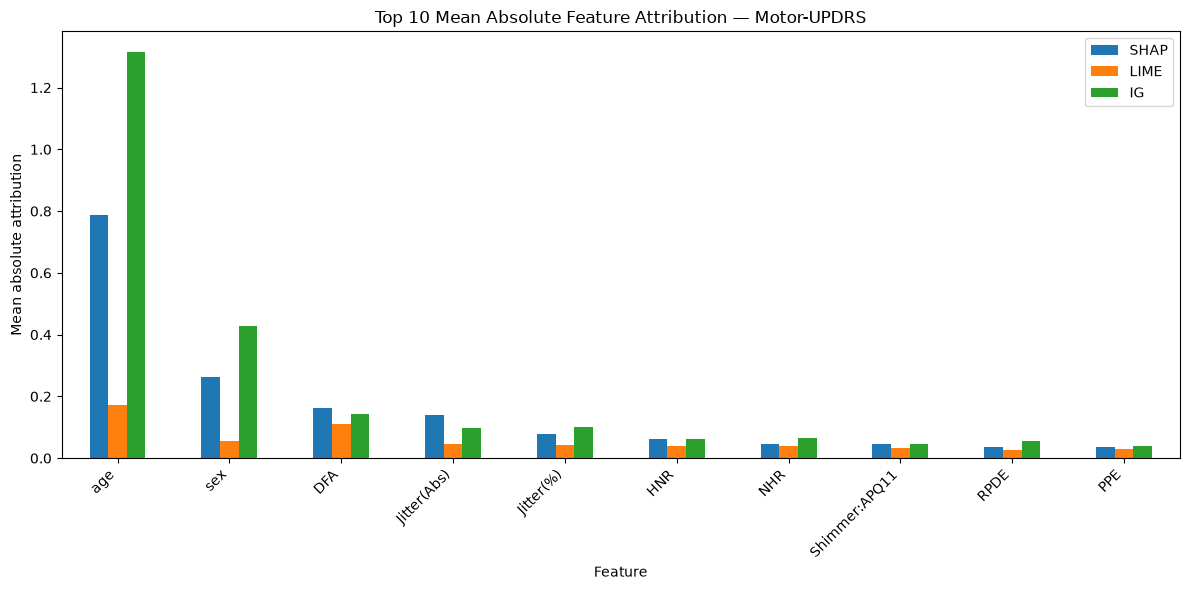

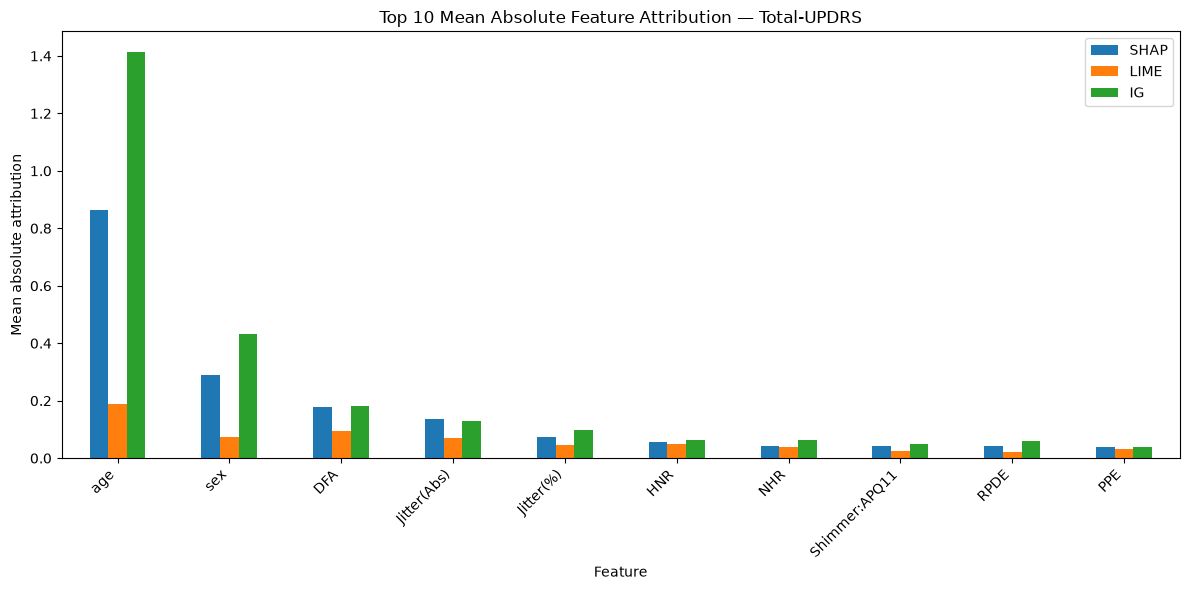

In [15]:

# Mean absolute attribution visualization
def mean_abs_attribution(target_name):
    sub = results_df[results_df["target"] == target_name]
    rows = []

    for fname in feature_names:
        rows.append({
            "feature": fname,
            "SHAP": sub[f"SHAP::{fname}"].abs().mean(),
            "LIME": sub[f"LIME::{fname}"].abs().mean(),
            "IG": sub[f"IG::{fname}"].abs().mean(),
        })

    return (
        pd.DataFrame(rows)
        .set_index("feature")
        .sort_values("SHAP", ascending=False)
        .head(10)
    )

for target_name in ["Motor-UPDRS", "Total-UPDRS"]:
    ax = mean_abs_attribution(target_name).plot(
        kind="bar", figsize=(12, 6)
    )
    ax.set_title(
        f"Top 10 Mean Absolute Feature Attribution — {target_name}"
    )
    ax.set_ylabel("Mean absolute attribution")
    ax.set_xlabel("Feature")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


In [16]:

# Export everything needed for the paper/reviewer response
OUT_DIR = ROOT / "results"
OUT_DIR.mkdir(exist_ok=True)

results_df.to_csv(
    OUT_DIR / "r3_feature_attribution_comparison.csv",
    index=False
)
summary_metrics.to_csv(
    OUT_DIR / "r3_feature_attribution_summary.csv",
    index=False
)
counterfactual_df.to_csv(
    OUT_DIR / "r3_counterfactual_results.csv",
    index=False
)
cf_summary.to_csv(
    OUT_DIR / "r3_counterfactual_summary.csv",
    index=False
)
sample_df.to_csv(
    OUT_DIR / "r3_selected_test_samples.csv",
    index=False
)

print("R3 files written to:", OUT_DIR.resolve())


R3 files written to: /mnt/games-code/parkinsons-multi-model-master-slave/results



## Interpretation guardrails

Do not conclude that one XAI method is universally superior from this experiment.

The defensible conclusions are:

- SHAP, LIME and Integrated Gradients can be compared through Top-5 overlap and rank correlation when applied to the same NN expert and same held-out patients.
- Counterfactual explanations are complementary rather than directly interchangeable with feature-attribution methods.
- The adaptive framework additionally exposes patient-specific RF/NN expert allocation, which conventional feature-attribution methods do not represent.
- The counterfactual procedure is a constrained computational explanation, **not a clinical recommendation**.
